In [19]:
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from numpy.polynomial.legendre import legvander

In [20]:
SEED = 42                           # SEED wird dafür gebraucht, dass sich nicht bei jedem Lauf die Anfangsbedingungen, die Trainings-, Validierungsdaten und die Anfänglichen Gewichte des Autoencoders verändern
                                    # Damit wird ein Autoencoder mit verschiedenen Aktivierungsfunktionen vergleichbar
np.random.seed(SEED)
torch.manual_seed(SEED)

rng = np.random.default_rng(SEED)

# Anzahl der Trajektorien
N_TRAIN_TRAJECTORIES = 100
N_VAL_TRAJECTORIES = 20

AUTOENCODER_EPOCHS = 700
DYNAMICS_EPOCHS = 700

AUTOENCODER_LEARNING_RATE = 3e-4
DYNAMICS_LEARNING_RATE = 3e-4


# Trainingsparameter
BATCH_SIZE = 1024
EPOCHS = 700                       # Anzahl der Epochen, die trainiert werden. 1 Epoche = Modell hat alle Trainingsdateien gesehen
LEARNING_RATE = 3e-4
PRINT_FREQUENCY = 10

NOISE_STRENGTH = 0.05

Definition des Lorenzsystems

In [21]:
def lorenz(state, t, sigma=10., rho=28., beta=8/3):

    x, y, z = state
    dx = sigma * (y - x)
    dy = x * (rho - z) - y
    dz = x * y - beta * z

    return [dx, dy, dz]

Räumliche Basis

In [22]:
t = np.arange(0.0, 5.0, 0.02)       # Erzeugen eines Zeitvektors. t = 0.0 bis t = 5.0 Schrittweite = 0.02. Ergibt 250 Zeitpunkte
grid = np.linspace(-1, 1, 128)      # Erzeugt 128 gleichmäßig verteilte Punkte auf dem Intervall [-1, 1]
U = legvander(grid, 5)              # Erzeugt Vandermonde-Matrix für Legendre-Polynome. Für jeden Punkt aus grid werden die ersten 6 Legendre-Polynome ausgewertet.

Erstellen des künstlichen 128 dimensionalen Datensatz

In [23]:
def create_lorenz_dataset(number_of_trajectories, noise_strength=0):
    ic_means = np.array([0.0, 0.0, 25.0])                                                                       # Mittelpunkte der Verteilung der Anfangszustände
    ic_widths = 2.0 * np.array([36.0, 48.0, 41.0])                                                              # Intervallbreiten
    initial_conditions = (ic_widths * (np.random.rand(number_of_trajectories, 3) - 0.5)) + ic_means             # Erstellen der zufälligen Anfangszustände

    Z_raw = np.stack([odeint(lorenz, z0, t) for z0 in initial_conditions])

    Z_scaled = Z_raw / 40.0                                                                                     # Normalisierung

    Z_scaled = Z_scaled.astype(np.float32)                                                                      # Wandelt in Gleitkommazahl um (Für PyTorch)

    modes = np.concatenate([                                                                                    # Erstellen der Gleichung aus dem Paper: z1(t), z2(t), z3(t), z1(t)^3, z2(t)^3, z3(t)^3
        Z_scaled,
        Z_scaled**3
    ], axis=2)

    X = modes @ U.T                                                                                             # modes wird mit transponierter Legendre-Matrix multipliziert

    return Z_raw, Z_scaled, X.astype(np.float32)

Trainings, Validierrungs- und Testdaten erzeugen

In [24]:
# Daten werden nach Trajektorien getrennt
Z_train_raw, Z_train, X_train = create_lorenz_dataset(N_TRAIN_TRAJECTORIES)          #
Z_val_raw, Z_val, X_val = create_lorenz_dataset(N_VAL_TRAJECTORIES)

In [25]:
X_train_flat = X_train.reshape(-1, 128)
X_val_flat = X_val.reshape(-1, 128)

X_train_tensor = torch.from_numpy(
    np.ascontiguousarray(X_train_flat)
).float()

X_val_tensor = torch.from_numpy(
    np.ascontiguousarray(X_val_flat)
).float()


autoencoder_dataset = TensorDataset(
    X_train_tensor
)

autoencoder_loader = DataLoader(
    autoencoder_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False
)

t- und t+1-Paare für die latente Dynamik

In [26]:
# X(t): alle Zeitpunkte außer dem letzten
X_train_t = X_train[:, :-1, :].reshape(-1, 128)
X_val_t = X_val[:, :-1, :].reshape(-1, 128)

# X(t+1): alle Zeitpunkte außer dem ersten
X_train_tp1 = X_train[:, 1:, :].reshape(-1, 128)
X_val_tp1 = X_val[:, 1:, :].reshape(-1, 128)

# Erstellt PyTorch tensor und ascontiguousarray sorgt dafür, dass die Daten zusammenhängend im Speicher liegen
X_train_t_tensor = torch.from_numpy(np.ascontiguousarray(X_train_t)).float()
X_train_tp1_tensor = torch.from_numpy(np.ascontiguousarray(X_train_tp1)).float()
X_val_t_tensor = torch.from_numpy(np.ascontiguousarray(X_val_t)).float()
X_val_tp1_tensor = torch.from_numpy(np.ascontiguousarray(X_val_tp1)).float()


dynamics_dataset = TensorDataset(
    X_train_t_tensor,
    X_train_tp1_tensor
)

dynamics_loader = DataLoader(
    dynamics_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False
)

Autoencoder-Daten: torch.Size([25000, 128])
X_train_t:         torch.Size([24900, 128])
X_train_tp1:       torch.Size([24900, 128])
X_val_t:           torch.Size([4980, 128])
X_val_tp1:         torch.Size([4980, 128])


Erstellen des Autoencoders

In [28]:
class PredictiveAutoencoder(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(128, 64),
            nn.SiLU(),

            nn.Linear(64, 32),
            nn.SiLU(),

            nn.Linear(32, 16),
            nn.SiLU(),

            nn.Linear(16, 3)
        )

        """self.latent_dynamics = nn.Sequential(
            nn.Linear(3, 16),
            nn.SiLU(),
            nn.Linear(16, 3)
        )"""

        self.decoder = nn.Sequential(
            nn.Linear(3, 16),
            nn.SiLU(),

            nn.Linear(16, 32),
            nn.SiLU(),

            nn.Linear(32, 64),
            nn.SiLU(),

            nn.Linear(64, 128)
        )

    # def forward(self, x_t, x_tp1):
    def forward(self, x):

        z = self.encoder(x)
        x_hat = self.decoder(z)

        return x_hat, z




    """  "  # Aktueller latenter Zustand
        z_t = self.encoder(x_t)

        # Tatsächlicher latenter Folgezustand
        z_tp1 = self.encoder(x_tp1)

        # Rekonstruktion des aktuellen Zustands
        x_t_hat = self.decoder(z_t)

        # Vorhergesagte latente Änderung
        delta_z = self.latent_dynamics(z_t)

        # Latente Ein-Schritt-Vorhersage
        z_tp1_hat = z_t + delta_z

        # Rekonstruktion des vorhergesagten Folgezustands
        x_tp1_hat = self.decoder(z_tp1_hat)"

        return x_t_hat, z_tp1, z_tp1_hat, x_tp1_hat"""



Berechnen des Rekonstruktionsfehler

Trainieren des Autoencoders

In [29]:
model = PredictiveAutoencoder()                                 # Erstellen des Models
criterion = nn.MSELoss()


autoencoder_optimizer = torch.optim.Adam(
    model.parameters(),
    lr=AUTOENCODER_LEARNING_RATE
)

autoencoder_scheduler = (
    torch.optim.lr_scheduler.CosineAnnealingLR(
        autoencoder_optimizer,
        T_max=AUTOENCODER_EPOCHS,
        eta_min=1e-6
    )
)


autoencoder_train_history = []
autoencoder_val_history = []


for epoch in range(AUTOENCODER_EPOCHS):

    model.train()

    total_train_loss = 0.0
    total_train_samples = 0


    for (x_batch,) in autoencoder_loader:

        autoencoder_optimizer.zero_grad()

        if NOISE_STRENGTH > 0:
            noise = NOISE_STRENGTH * torch.randn_like(x_batch)
            x_batch_noisy = x_batch + noise
        else:
            x_batch_noisy = x_batch


        # X -> Encoder -> z -> Decoder -> X_hat
        x_hat, z = model(x_batch_noisy)


        reconstruction_loss = criterion(x_hat, x_batch)             # Warum hier nicht x_batch_nois anstatt von x_batch

        reconstruction_loss.backward()
        autoencoder_optimizer.step()

        batch_size = x_batch.shape[0]

        total_train_loss += (
            reconstruction_loss.item() * batch_size
        )

        total_train_samples += batch_size


    train_loss = (total_train_loss / total_train_samples)

    autoencoder_train_history.append(train_loss)


    # Validierung des Autoencoders
    model.eval()

    with torch.inference_mode():

        X_val_hat, Z_val_encoded = model(X_val_tensor)

        val_loss = criterion(X_val_hat, X_val_tensor)


    autoencoder_val_history.append(val_loss.item())

    autoencoder_scheduler.step()


    if epoch % PRINT_FREQUENCY == 0 or epoch == AUTOENCODER_EPOCHS - 1:

        print(
            f"Autoencoder | "
            f"Epoch {epoch:4d} | "
            f"Training: {train_loss:.6e} | "
            f"Validierung: {val_loss.item():.6e}"
        )

Autoencoder | Epoch    0 | Training: 1.981520e-01 | Validierung: 1.802831e-01
Autoencoder | Epoch   10 | Training: 1.943835e-02 | Validierung: 1.723794e-02
Autoencoder | Epoch   20 | Training: 6.285563e-03 | Validierung: 5.697304e-03
Autoencoder | Epoch   30 | Training: 4.805844e-03 | Validierung: 4.341395e-03
Autoencoder | Epoch   40 | Training: 4.201158e-03 | Validierung: 3.843415e-03
Autoencoder | Epoch   50 | Training: 3.791403e-03 | Validierung: 3.529690e-03
Autoencoder | Epoch   60 | Training: 3.413608e-03 | Validierung: 3.193563e-03
Autoencoder | Epoch   70 | Training: 2.749261e-03 | Validierung: 2.526484e-03
Autoencoder | Epoch   80 | Training: 1.940058e-03 | Validierung: 1.745142e-03
Autoencoder | Epoch   90 | Training: 1.577794e-03 | Validierung: 1.408982e-03
Autoencoder | Epoch  100 | Training: 1.411569e-03 | Validierung: 1.269711e-03
Autoencoder | Epoch  110 | Training: 1.255579e-03 | Validierung: 1.144446e-03
Autoencoder | Epoch  120 | Training: 1.073446e-03 | Validierung:

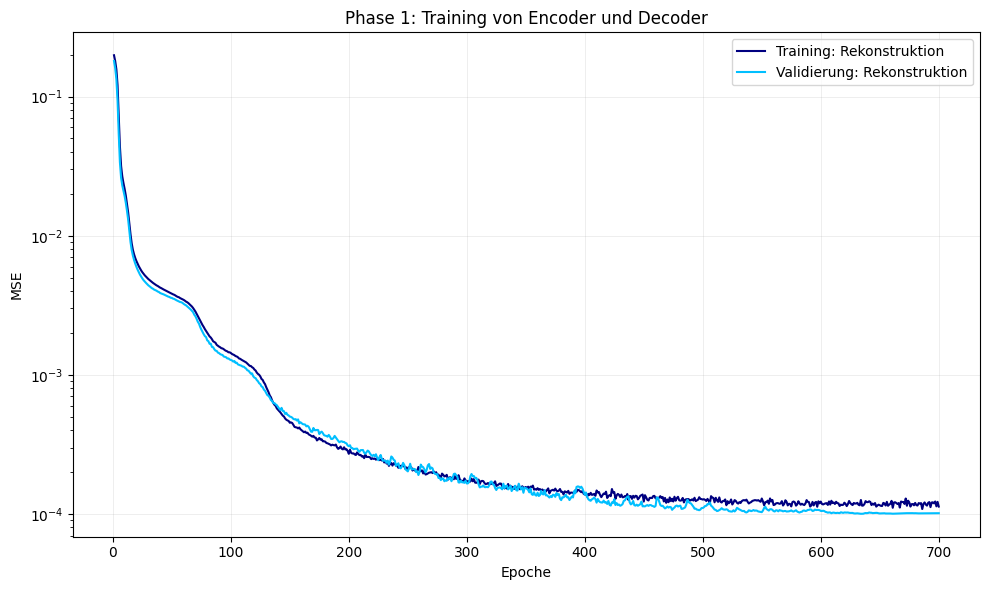

In [30]:
autoencoder_epochs = np.arange(
    1,
    len(autoencoder_train_history) + 1
)

plt.figure(figsize=(10, 6))

plt.plot(
    autoencoder_epochs,
    autoencoder_train_history,
    color="navy",
    linewidth=1.5,
    label="Training: Rekonstruktion"
)

plt.plot(
    autoencoder_epochs,
    autoencoder_val_history,
    color="deepskyblue",
    linewidth=1.5,
    label="Validierung: Rekonstruktion"
)

plt.yscale("log")

plt.xlabel("Epoche")
plt.ylabel("MSE")
plt.title("Phase 1: Training von Encoder und Decoder")

plt.grid(
    True,
    alpha=0.3
)

plt.legend()
plt.tight_layout()
plt.show()

In [31]:
# Encoder einfrieren
for parameter in model.encoder.parameters():
    parameter.requires_grad = False

# Decoder einfrieren
for parameter in model.decoder.parameters():
    parameter.requires_grad = False

# Latente Dynamik ergänzen:

model.latent_dynamics = nn.Sequential(

    nn.Linear(3, 16),
    nn.SiLU(),

    nn.Linear(16, 32),
    nn.SiLU(),

    nn.Linear(32, 64),
    nn.SiLU(),

    nn.Linear(64, 32),
    nn.SiLU(),

    nn.Linear(32, 16),
    nn.SiLU(),

    nn.Linear(16,3)
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(
    f"Trainierbare Parameter in Phase 2: "
    f"{trainable_parameters}"
)

dynamics_optimizer = torch.optim.Adam(
    model.latent_dynamics.parameters(),
    lr=DYNAMICS_LEARNING_RATE
)

dynamics_scheduler = (
    torch.optim.lr_scheduler.CosineAnnealingLR(
        dynamics_optimizer,
        T_max=DYNAMICS_EPOCHS,
        eta_min=1e-6
    )
)

Trainierbare Parameter in Phase 2: 5379


In [32]:
dynamics_train_history = []
dynamics_val_history = []

dynamics_train_latent_history = []
dynamics_train_prediction_history = []

dynamics_val_latent_history = []
dynamics_val_prediction_history = []

dynamics_train_total_history = []

dynamics_val_total_history = []
dynamics_val_reconstruction_history = []
dynamics_val_latent_history = []
dynamics_val_prediction_history = []
for epoch in range(DYNAMICS_EPOCHS):

    # Encoder und Decoder bleiben fest
    model.encoder.eval()
    model.decoder.eval()

    # Nur latent_dynamics wird trainiert
    model.latent_dynamics.train()



    total_train_loss = 0.0
    # total_latent_loss = 0.0
    # total_prediction_loss = 0.0
    total_train_samples = 0


    for x_t, x_tp1 in dynamics_loader:

        dynamics_optimizer.zero_grad()


        if NOISE_STRENGTH > 0:
            noise = NOISE_STRENGTH * torch.randn_like(x_t)
            x_t_noisy = x_t + noise
        else:
            x_t_noisy = x_t
        # Encoder und Decoder sind bereits trainiert
        # Für die Encoder-Berechnungen werden keine Gradienten benötigt
        with torch.no_grad():
            z_t = model.encoder(x_t_noisy)
            z_tp1 = model.encoder(x_tp1)
            x_t_hat = model.decoder(z_t)


        # Vorhergesagte Veränderung
        delta_z = model.latent_dynamics(z_t)

        # Latente Ein-Schritt-Vorhersage
        z_tp1_hat = z_t + delta_z

        x_tp1_hat = model.decoder(z_tp1_hat)

        reconstruction_loss = criterion(x_t_hat, x_t)

        latent_loss = criterion(z_tp1_hat, z_tp1)

        prediction_loss = criterion(x_tp1_hat, x_tp1)

        optimization_loss = (0.1 * latent_loss + prediction_loss)

        comparison_loss = (reconstruction_loss + 0.1 * latent_loss + prediction_loss)

        optimization_loss.backward()

        # Nur latent_dynamics wird aktualisiert
        dynamics_optimizer.step()

        batch_size = x_t.shape[0]

        total_train_loss += (comparison_loss.item() * batch_size)

        total_train_samples += batch_size

    train_loss = (total_train_loss / total_train_samples)
    dynamics_train_history.append(train_loss)

    model.encoder.eval()
    model.decoder.eval()
    model.latent_dynamics.eval()

    with torch.inference_mode():
        z_val_t = model.encoder(X_val_t_tensor)
        z_val_tp1 = model.encoder(X_val_tp1_tensor)
        X_val_t_hat = model.decoder(z_val_t)
        delta_z_val = model.latent_dynamics(z_val_t)
        z_val_tp1_hat = (z_val_t + delta_z_val)
        X_val_tp1_hat = model.decoder(z_val_tp1_hat)

        val_reconstruction_loss = criterion(X_val_t_hat, X_val_t_tensor)

        val_latent_loss = criterion(z_val_tp1_hat, z_val_tp1)
        val_prediction_loss = criterion(X_val_tp1_hat, X_val_tp1_tensor)
        val_total_loss = (val_reconstruction_loss + 0.1 * val_latent_loss + val_prediction_loss)

    dynamics_val_total_history.append(val_total_loss.item())

    dynamics_val_reconstruction_history.append(val_reconstruction_loss.item())

    dynamics_val_latent_history.append(val_latent_loss.item())

    dynamics_val_prediction_history.append(val_prediction_loss.item())
    dynamics_scheduler.step()


    if epoch % PRINT_FREQUENCY == 0 or epoch == DYNAMICS_EPOCHS - 1:

        print(
            f"Dynamik | "
            f"Epoch {epoch:4d} | "
            f"Training gesamt: "
            f"{train_loss:.6e} | "
            f"Validierung gesamt: "
            f"{val_total_loss.item():.6e} | "
            f"Rekonstruktion: "
            f"{val_reconstruction_loss.item():.6e} | "
            f"Latent: "
            f"{val_latent_loss.item():.6e} | "
            f"Vorhersage: "
            f"{val_prediction_loss.item():.6e}"
        )

Dynamik | Epoch    0 | Training gesamt: 1.380531e-01 | Validierung gesamt: 1.331542e-01 | Rekonstruktion: 1.016465e-04 | Latent: 1.281694e+00 | Vorhersage: 4.883161e-03
Dynamik | Epoch   10 | Training gesamt: 6.618229e-02 | Validierung gesamt: 6.059385e-02 | Rekonstruktion: 1.016465e-04 | Latent: 5.851412e-01 | Vorhersage: 1.978076e-03
Dynamik | Epoch   20 | Training gesamt: 3.959337e-02 | Validierung gesamt: 3.470629e-02 | Rekonstruktion: 1.016465e-04 | Latent: 3.295687e-01 | Vorhersage: 1.647780e-03
Dynamik | Epoch   30 | Training gesamt: 2.829540e-02 | Validierung gesamt: 2.775900e-02 | Rekonstruktion: 1.016465e-04 | Latent: 2.616020e-01 | Vorhersage: 1.497145e-03
Dynamik | Epoch   40 | Training gesamt: 2.206604e-02 | Validierung gesamt: 2.226115e-02 | Rekonstruktion: 1.016465e-04 | Latent: 2.065039e-01 | Vorhersage: 1.509114e-03
Dynamik | Epoch   50 | Training gesamt: 1.879810e-02 | Validierung gesamt: 1.809858e-02 | Rekonstruktion: 1.016465e-04 | Latent: 1.645005e-01 | Vorhersage:

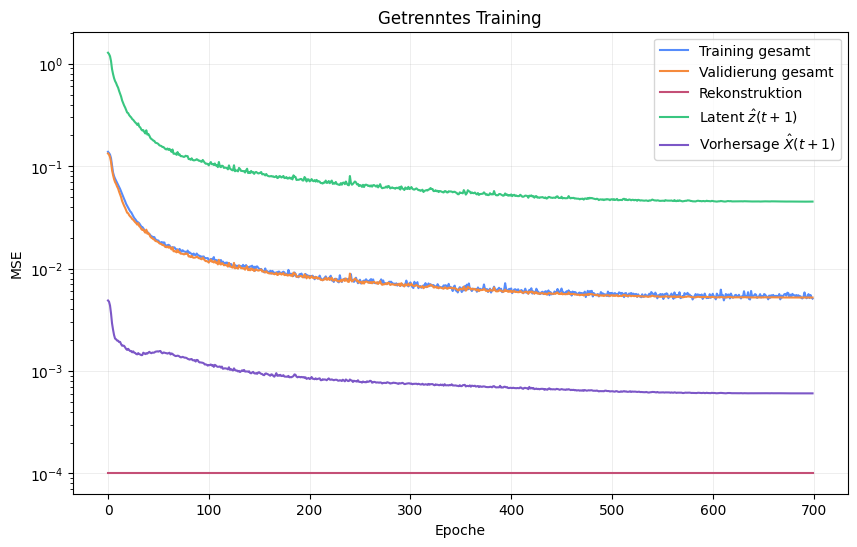

In [33]:
plt.figure(figsize=(10, 6))

plt.plot(dynamics_train_history, label="Training gesamt") # Durchschnittlicher Gesamtfehler auf den Trainingsdaten. Setzt sich aus dem comparision_loss zusammen. Am Ende wird Mittelwert über alle Trainingsbeispiele genommen.

plt.plot(dynamics_val_total_history, label="Validierung gesamt")                # Gesamtfehler auf Validierungsdaten

plt.plot(dynamics_val_reconstruction_history, label="Rekonstruktion")           # Wie gut der Autoencoder den aktuellen Zustand wieder herstellt

plt.plot(dynamics_val_latent_history, label=r"Latent $\hat{z}(t+1)$")           # Vergleicht vorhergesagten latenten Folgezustand mit dem tatsächlichen latenten Folgezustand

plt.plot(dynamics_val_prediction_history, label=r"Vorhersage $\hat{X}(t+1)$")   # Wie gut kann das Modell aus X(t) den nächsten 128d Zustand X(t+1) Vorhersagen?



plt.yscale("log")

plt.xlabel("Epoche")
plt.ylabel("MSE")

plt.title("Getrenntes Training")

plt.legend()
plt.grid(alpha=0.3)

plt.show()